# CodeAlpha Machine Learning Internship
## Task 3 — Handwritten Character Recognition

**Goal:** Classify handwritten digits (0–9) and uppercase letters (A–Z) with a CNN.

| Item | Detail |
|------|--------|
| Datasets | MNIST (digits) + EMNIST Letters (A–Z) |
| Classes | 36 (unified label space) |
| Model | CharCNN (3-stage Conv-BN-ReLU-MaxPool) |
| Extension | Untrained CRNN architecture demo for word-level sequence recognition |
| Runtime | CPU-compatible; fixed random seeds for reproducibility |

**How to run**
1. Put MNIST/EMNIST under `./data` (or set `DATA_DIR` in the setup cell).
2. Keep `DOWNLOAD = False` if data is already present.
3. Restart kernel → Run All.
4. Training prints progress every 100 batches (~2–3 min/epoch on CPU). It is not stuck.


## 1. Environment Setup & Reproducibility


In [1]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, ConcatDataset, random_split
import torchvision.transforms as transforms
import torchvision.datasets as datasets

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- 36-class label maps ---
CLASS_NAMES = [str(i) for i in range(10)] + [chr(ord('A') + i) for i in range(26)]
LABEL_MAP = {i: n for i, n in enumerate(CLASS_NAMES)}
CHAR_TO_LABEL = {n: i for i, n in enumerate(CLASS_NAMES)}
NUM_CLASSES = 36

# Data root: change this if your MNIST/EMNIST folders live elsewhere
DATA_DIR = r"C:\Users\ADMIN\Documents\Projects\CodeAlpha\data"
# If data is already downloaded, keep DOWNLOAD=False to avoid network stalls
DOWNLOAD = False

print(f'Device: {device}  |  Torch: {torch.__version__}  |  Classes: {NUM_CLASSES}')
print(f'DATA_DIR={os.path.abspath(DATA_DIR)}  |  DOWNLOAD={DOWNLOAD}')
print(f'Class map: 0-9 = digits | 10-35 = A-Z')


Device: cpu  |  Torch: 2.14.1+cpu  |  Classes: 36
DATA_DIR=C:\Users\ADMIN\Documents\Projects\CodeAlpha\data  |  DOWNLOAD=False
Class map: 0-9 = digits | 10-35 = A-Z


## 2. Dataset Loading & Orientation Correction

EMNIST Letters stores images in **column-major** order (transposed relative to MNIST).
`PIL.Image.TRANSPOSE` restores upright orientation. This is applied inside the EMNIST
transform pipelines only — MNIST needs no orientation fix.

**Label mapping:** EMNIST Letters uses targets 1–26 for A–Z. We map them to classes
10–35 via `y + 9`. MNIST targets 0–9 are used as-is.


In [2]:
def fix_emnist_orientation(img):
    """Restore EMNIST Letters images from column-major storage to upright."""
    return img.transpose(Image.TRANSPOSE)

def denormalize(t):
    """Invert Normalize(mean=0.5, std=0.5) for visualisation."""
    return t * 0.5 + 0.5

os.makedirs(DATA_DIR, exist_ok=True)

# Deterministic transforms (val / test / inference)
clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
emnist_clean_transform = transforms.Compose([
    transforms.Lambda(fix_emnist_orientation),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

# Stochastic transforms (train only)
aug_transform = transforms.Compose([
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
emnist_aug_transform = transforms.Compose([
    transforms.Lambda(fix_emnist_orientation),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

print('Transform pipelines ready (augmentation applied to train split only).')


Transform pipelines ready (augmentation applied to train split only).


Loading EMNIST Letters for orientation check...
Found 6/6 chars after scanning 46 images


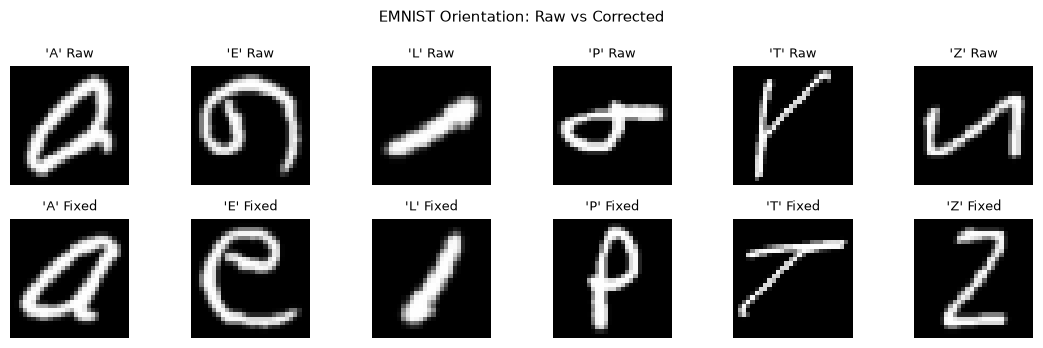

Orientation verified: Image.TRANSPOSE corrects EMNIST column-major storage.


In [3]:
# Orientation check (uses existing data when DOWNLOAD=False)
print('Loading EMNIST Letters for orientation check...')
ds_raw = datasets.EMNIST(DATA_DIR, split='letters', train=True, download=DOWNLOAD)

target_chars = list('AELPTZ')
orientation_samples = {}
# Bound the scan so this cell cannot hang forever
MAX_SCAN = 5000
for i, (img, lbl) in enumerate(ds_raw):
    ch = chr(ord('A') + lbl - 1)  # EMNIST letters targets are 1..26
    if ch in target_chars and ch not in orientation_samples:
        orientation_samples[ch] = img
    if len(orientation_samples) == len(target_chars) or i >= MAX_SCAN:
        break

chars_to_show = [c for c in target_chars if c in orientation_samples]
assert len(chars_to_show) > 0, 'No sample characters found — check DATA_DIR / EMNIST files'
print(f'Found {len(chars_to_show)}/{len(target_chars)} chars after scanning {i+1} images')

fig, axes = plt.subplots(2, len(chars_to_show), figsize=(11, 3.5))
if len(chars_to_show) == 1:
    axes = np.array(axes).reshape(2, 1)
for col, ch in enumerate(chars_to_show):
    raw_img = orientation_samples[ch]
    axes[0, col].imshow(np.array(raw_img), cmap='gray')
    axes[0, col].set_title(f"'{ch}' Raw", fontsize=9)
    axes[0, col].axis('off')
    axes[1, col].imshow(np.array(raw_img.transpose(Image.TRANSPOSE)), cmap='gray')
    axes[1, col].set_title(f"'{ch}' Fixed", fontsize=9)
    axes[1, col].axis('off')
axes[0, 0].set_ylabel('Before\nTRANSPOSE', fontsize=8)
axes[1, 0].set_ylabel('After\n(Upright)', fontsize=8)
plt.suptitle('EMNIST Orientation: Raw vs Corrected', fontsize=11)
plt.tight_layout()
plt.show()
print('Orientation verified: Image.TRANSPOSE corrects EMNIST column-major storage.')


In [4]:
# Load MNIST + EMNIST (no re-download when DOWNLOAD=False)
print('Loading datasets (this can take 30–90s the first time while files are indexed)...')
t_load = time.time()

mnist_train_aug = datasets.MNIST(DATA_DIR, train=True, download=DOWNLOAD, transform=aug_transform)
emnist_train_aug = datasets.EMNIST(
    DATA_DIR, split='letters', train=True, download=DOWNLOAD,
    transform=emnist_aug_transform,
    target_transform=transforms.Lambda(lambda y: y + 9),  # 1..26 → 10..35
)

mnist_train_clean = datasets.MNIST(DATA_DIR, train=True, download=False, transform=clean_transform)
emnist_train_clean = datasets.EMNIST(
    DATA_DIR, split='letters', train=True, download=False,
    transform=emnist_clean_transform,
    target_transform=transforms.Lambda(lambda y: y + 9),
)

mnist_test = datasets.MNIST(DATA_DIR, train=False, download=False, transform=clean_transform)
emnist_test = datasets.EMNIST(
    DATA_DIR, split='letters', train=False, download=False,
    transform=emnist_clean_transform,
    target_transform=transforms.Lambda(lambda y: y + 9),
)
print(f'Datasets constructed in {time.time()-t_load:.1f}s')

# Sanity: label ranges
_sample_mnist_lbl = mnist_train_clean.targets[:5].tolist()
_sample_emnist_lbl = [emnist_train_clean[i][1] for i in range(5)]
assert all(0 <= x <= 9 for x in _sample_mnist_lbl), 'MNIST labels out of range'
assert all(10 <= x <= 35 for x in _sample_emnist_lbl), 'EMNIST mapped labels out of range'
print(f'MNIST sample labels (expect 0-9):   {_sample_mnist_lbl}')
print(f'EMNIST sample labels (expect 10-35): {_sample_emnist_lbl}')

full_aug = ConcatDataset([mnist_train_aug, emnist_train_aug])
full_clean = ConcatDataset([mnist_train_clean, emnist_train_clean])
full_test = ConcatDataset([mnist_test, emnist_test])

VAL_RATIO = 0.10
n_total = len(full_aug)
val_size = int(n_total * VAL_RATIO)
train_size = n_total - val_size

g = torch.Generator().manual_seed(SEED)
train_aug_split, _ = random_split(full_aug, [train_size, val_size], generator=g)
g2 = torch.Generator().manual_seed(SEED)
_, val_split = random_split(full_clean, [train_size, val_size], generator=g2)

train_idx = set(train_aug_split.indices)
val_idx = set(val_split.indices)
assert train_idx.isdisjoint(val_idx), 'Train/val index overlap detected'
assert len(train_idx) + len(val_idx) == n_total

BATCH_SIZE = 128
train_loader = DataLoader(train_aug_split, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_split, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(full_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f'Train (aug): {len(train_aug_split):,}  |  Val (clean): {len(val_split):,}  |  Test (clean): {len(full_test):,}')
print(f'Train ∩ Val indices: {len(train_idx & val_idx)} (must be 0)')
print(f'Batches per epoch: train={len(train_loader)}, val={len(val_loader)}')


Loading datasets (this can take 30–90s the first time while files are indexed)...
Datasets constructed in 0.4s
MNIST sample labels (expect 0-9):   [5, 0, 4, 1, 9]
EMNIST sample labels (expect 10-35): [32, 16, 25, 24, 32]
Train (aug): 166,320  |  Val (clean): 18,480  |  Test (clean): 30,800
Train ∩ Val indices: 0 (must be 0)
Batches per epoch: train=1300, val=145


## 3. Exploratory Data Analysis

Augmentation (rotation ±10°, affine translate/scale) is applied **only** on the
training split. Validation and test use deterministic clean transforms.


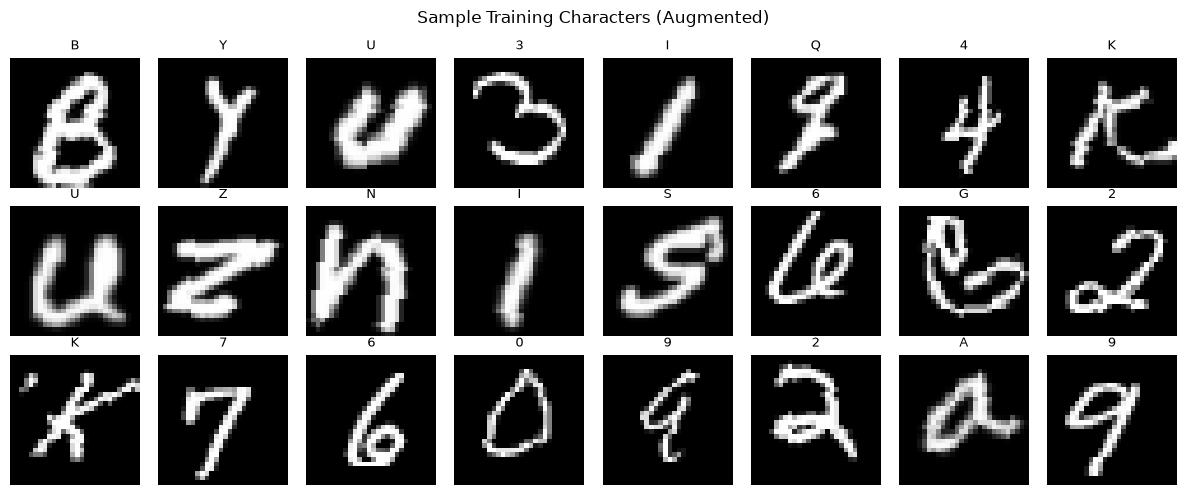

In [5]:
# Sample grid from the augmented training split
step = max(1, len(train_aug_split) // 24)
indices = [i * step for i in range(24)]

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for pi, si in enumerate(indices):
    img_t, label = train_aug_split[si]
    axes[pi // 8, pi % 8].imshow(denormalize(img_t).squeeze().numpy(), cmap='gray')
    axes[pi // 8, pi % 8].set_title(LABEL_MAP[label], fontsize=9)
    axes[pi // 8, pi % 8].axis('off')
plt.suptitle('Sample Training Characters (Augmented)', fontsize=12)
plt.tight_layout()
plt.show()


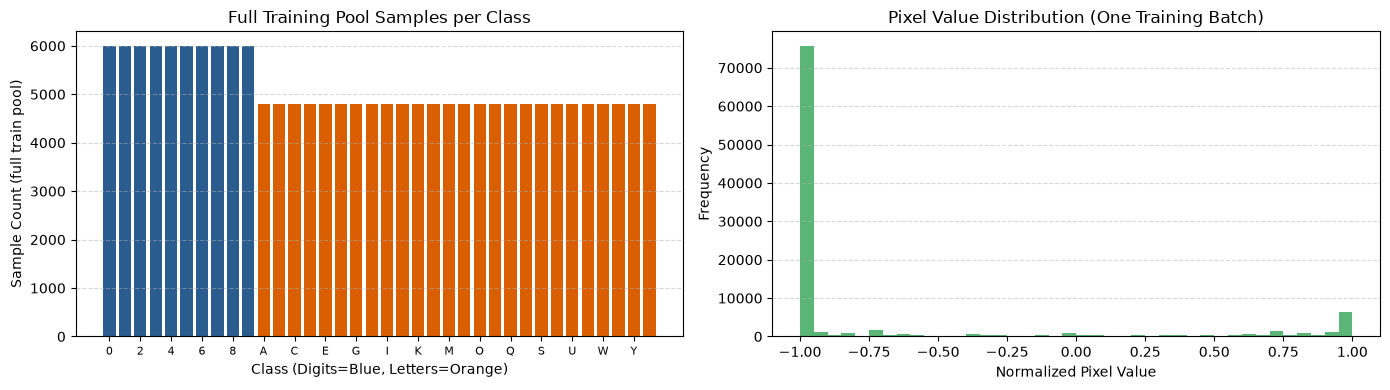

Digits ~6,000/class | Letters ~4,800/class (full train pools)


In [6]:
# Class counts from the original full training pools (before 90/10 split).
# After the random split each class is reduced by ~10%; relative balance is unchanged.
digits_per_class = 60000 // 10
letters_per_class = 124800 // 26
class_counts = [digits_per_class] * 10 + [letters_per_class] * 26

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.bar(range(NUM_CLASSES), class_counts,
        color=['#2b5c8f'] * 10 + ['#d95f02'] * 26, edgecolor='none')
ax1.set_xticks(range(0, NUM_CLASSES, 2))
ax1.set_xticklabels([LABEL_MAP[i] for i in range(0, NUM_CLASSES, 2)], fontsize=8)
ax1.set_xlabel('Class (Digits=Blue, Letters=Orange)')
ax1.set_ylabel('Sample Count (full train pool)')
ax1.set_title('Full Training Pool Samples per Class')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

batch_imgs, _ = next(iter(train_loader))
ax2.hist(batch_imgs.numpy().ravel(), bins=40, color='#31a354', edgecolor='none', alpha=0.8)
ax2.set_xlabel('Normalized Pixel Value')
ax2.set_ylabel('Frequency')
ax2.set_title('Pixel Value Distribution (One Training Batch)')
ax2.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
print(f'Digits ~{digits_per_class:,}/class | Letters ~{letters_per_class:,}/class (full train pools)')


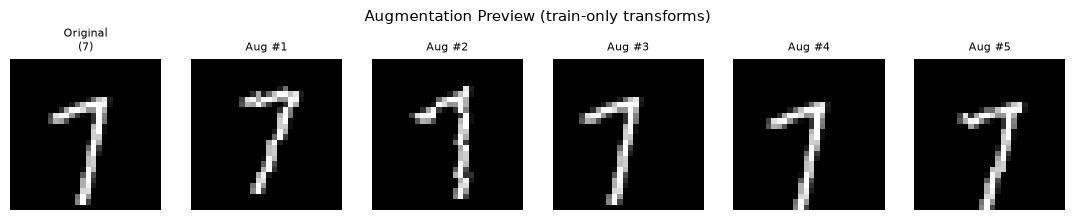

In [7]:
# Augmentation preview from a raw PIL image
raw_mnist = datasets.MNIST(DATA_DIR, train=True, download=False)
pil_img, lbl = raw_mnist[42]
aug_ops = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.95, 1.05)),
])

fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
axes[0].imshow(np.array(pil_img), cmap='gray')
axes[0].set_title(f'Original\n({LABEL_MAP[lbl]})', fontsize=8)
axes[0].axis('off')
for i in range(1, 6):
    axes[i].imshow(np.array(aug_ops(pil_img)), cmap='gray')
    axes[i].set_title(f'Aug #{i}', fontsize=8)
    axes[i].axis('off')
plt.suptitle('Augmentation Preview (train-only transforms)', fontsize=11)
plt.tight_layout()
plt.show()


## 4. CharCNN Architecture

Three convolutional stages (32 → 64 → 128 channels) with BatchNorm, ReLU, and
2×2 max-pooling, followed by a two-layer fully connected classifier with dropout.
Input: `[B, 1, 28, 28]` → Output: `[B, 36]`.


In [8]:
class CharCNN(nn.Module):
    def __init__(self, num_classes=36):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 7x7
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),  # 3x3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 256), nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = CharCNN(NUM_CLASSES).to(device)
dummy = torch.randn(1, 1, 28, 28, device=device)
with torch.no_grad():
    out = model(dummy)

params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert out.shape == (1, NUM_CLASSES), f'Unexpected output shape {out.shape}'
print(f'Input: {tuple(dummy.shape)}  →  Output: {tuple(out.shape)}')
print(f'Trainable parameters: {params:,}')


Input: (1, 1, 28, 28)  →  Output: (1, 36)
Trainable parameters: 397,540


## 5. Training & Validation

- **Loss:** Cross-entropy with mild label smoothing (0.05)
- **Optimizer:** AdamW (lr=0.002, weight decay=1e-4)
- **Scheduler:** ReduceLROnPlateau on validation loss
- **Checkpoint:** Best validation accuracy is saved to disk

Training accuracy reuses the **same logits** used for the loss (no extra forward pass).


In [9]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=1
)

NUM_EPOCHS = 3
CKPT_PATH = 'best_char_cnn.pth'
best_val_acc = 0.0
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

n_train_batches = len(train_loader)
print(f'Training for {NUM_EPOCHS} epochs | train={len(train_aug_split):,} | val={len(val_split):,}')
print(f'Expect ~2–3 minutes per epoch on CPU ({n_train_batches} train batches). Progress prints every 100 batches.')
print('-' * 72)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    # --- Train ---
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for bi, (imgs, lbls) in enumerate(train_loader, 1):
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        logits = model(imgs)                    # single forward pass
        loss = criterion(logits, lbls)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * lbls.size(0)
        correct += (logits.argmax(1) == lbls).sum().item()  # reuse logits
        total += lbls.size(0)
        if bi % 100 == 0 or bi == n_train_batches:
            print(f'  epoch {epoch}  batch {bi}/{n_train_batches}  '
                  f'loss={total_loss/total:.4f}  acc={correct/total*100:.1f}%', flush=True)
    tr_loss = total_loss / total
    tr_acc = correct / total * 100.0

    # --- Validate ---
    model.eval()
    v_loss = 0.0
    v_correct = 0
    v_total = 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            logits = model(imgs)
            v_loss += criterion(logits, lbls).item() * lbls.size(0)
            v_correct += (logits.argmax(1) == lbls).sum().item()
            v_total += lbls.size(0)
    vl = v_loss / v_total
    va = v_correct / v_total * 100.0

    scheduler.step(vl)
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va)

    flag = ''
    if va > best_val_acc:
        best_val_acc = va
        torch.save(model.state_dict(), CKPT_PATH)
        flag = ' [saved]'

    print(
        f'Epoch {epoch}/{NUM_EPOCHS} | '
        f'Train: loss={tr_loss:.4f} acc={tr_acc:.2f}% | '
        f'Val: loss={vl:.4f} acc={va:.2f}%  '
        f'({time.time() - t0:.0f}s){flag}',
        flush=True
    )

print(f'Best val acc: {best_val_acc:.2f}%  →  checkpoint: {CKPT_PATH}')


Training for 3 epochs | train=166,320 | val=18,480
Expect ~2–3 minutes per epoch on CPU (1300 train batches). Progress prints every 100 batches.
------------------------------------------------------------------------
  epoch 1  batch 100/1300  loss=2.0093  acc=49.4%
  epoch 1  batch 200/1300  loss=1.5879  acc=63.0%
  epoch 1  batch 300/1300  loss=1.3999  acc=69.3%
  epoch 1  batch 400/1300  loss=1.2878  acc=73.0%
  epoch 1  batch 500/1300  loss=1.2146  acc=75.5%
  epoch 1  batch 600/1300  loss=1.1602  acc=77.3%
  epoch 1  batch 700/1300  loss=1.1150  acc=78.8%
  epoch 1  batch 800/1300  loss=1.0785  acc=80.1%
  epoch 1  batch 900/1300  loss=1.0495  acc=81.0%
  epoch 1  batch 1000/1300  loss=1.0244  acc=81.9%
  epoch 1  batch 1100/1300  loss=1.0031  acc=82.6%
  epoch 1  batch 1200/1300  loss=0.9838  acc=83.2%
  epoch 1  batch 1300/1300  loss=0.9668  acc=83.8%
Epoch 1/3 | Train: loss=0.9668 acc=83.82% | Val: loss=0.6076 acc=94.36%  (449s) [saved]
  epoch 2  batch 100/1300  loss=0.7513  

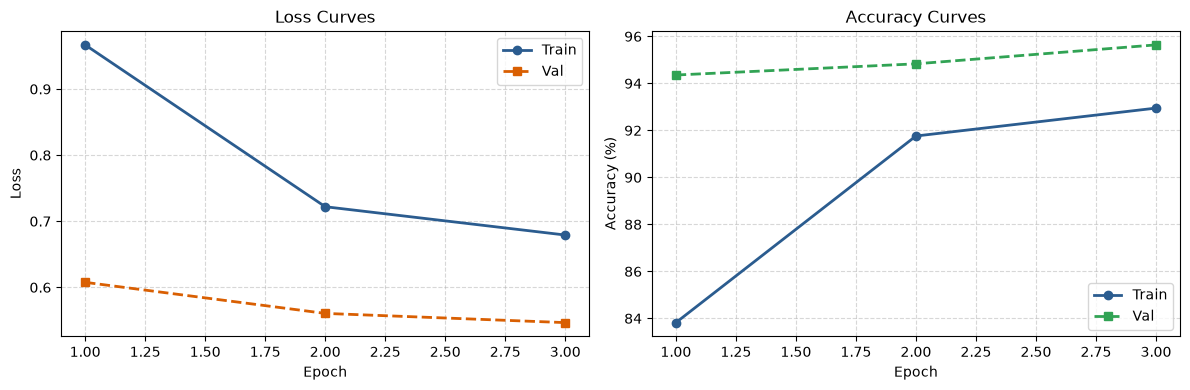

Best val accuracy (from history): 95.64%


In [10]:
# Load best checkpoint and plot curves
state = torch.load(CKPT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state)

ep_range = range(1, NUM_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(ep_range, history['train_loss'], 'o-', color='#2b5c8f', label='Train', lw=2)
ax1.plot(ep_range, history['val_loss'], 's--', color='#d95f02', label='Val', lw=2)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curves'); ax1.grid(linestyle='--', alpha=0.5); ax1.legend()

ax2.plot(ep_range, history['train_acc'], 'o-', color='#2b5c8f', label='Train', lw=2)
ax2.plot(ep_range, history['val_acc'], 's--', color='#31a354', label='Val', lw=2)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Accuracy Curves'); ax2.grid(linestyle='--', alpha=0.5); ax2.legend()

plt.tight_layout()
plt.show()
print(f'Best val accuracy (from history): {max(history["val_acc"]):.2f}%')


## 6. Full Test-Set Evaluation

The best validation checkpoint is evaluated **once** on the complete held-out test set
(MNIST test + EMNIST Letters test = 30,800 samples). Metrics are computed with pure
NumPy (no external metric library required).


In [11]:
def classification_report_np(y_true, y_pred, num_classes):
    """Accuracy + macro precision / recall / F1 without sklearn."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    acc = (y_true == y_pred).mean() * 100.0
    precisions, recalls, f1s = [], [], []
    for c in range(num_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        p = tp / (tp + fp) if (tp + fp) else 0.0
        r = tp / (tp + fn) if (tp + fn) else 0.0
        f = 2 * p * r / (p + r) if (p + r) else 0.0
        precisions.append(p); recalls.append(r); f1s.append(f)
    return acc, np.mean(precisions) * 100, np.mean(recalls) * 100, np.mean(f1s) * 100


def confusion_matrix_np(y_true, y_pred, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm


model.load_state_dict(torch.load(CKPT_PATH, map_location=device, weights_only=True))
model.eval()

y_true, y_pred = [], []
all_test_images = []
n_test_batches = len(test_loader)
print(f'Evaluating on full test set ({len(full_test):,} samples, {n_test_batches} batches)...')

t0 = time.time()
with torch.no_grad():
    for bi, (imgs, lbls) in enumerate(test_loader, 1):
        logits = model(imgs.to(device))
        preds = logits.argmax(1).cpu()
        y_true.extend(lbls.tolist())
        y_pred.extend(preds.tolist())
        if len(all_test_images) < 600:
            all_test_images.extend(list(imgs))
        if bi % 50 == 0 or bi == n_test_batches:
            print(f'  test batch {bi}/{n_test_batches}', flush=True)

test_acc, prec, rec, f1_mac = classification_report_np(y_true, y_pred, NUM_CLASSES)

print(f'Test samples    : {len(y_true):,} (full held-out set)')
print(f'Accuracy        : {test_acc:.2f}%')
print(f'Macro Precision : {prec:.2f}%')
print(f'Macro Recall    : {rec:.2f}%')
print(f'Macro F1-Score  : {f1_mac:.2f}%')
print(f'Elapsed         : {time.time() - t0:.1f}s')


Evaluating on full test set (30,800 samples, 241 batches)...
  test batch 50/241
  test batch 100/241
  test batch 150/241
  test batch 200/241
  test batch 241/241
Test samples    : 30,800 (full held-out set)
Accuracy        : 95.76%
Macro Precision : 95.55%
Macro Recall    : 95.52%
Macro F1-Score  : 95.52%
Elapsed         : 23.3s


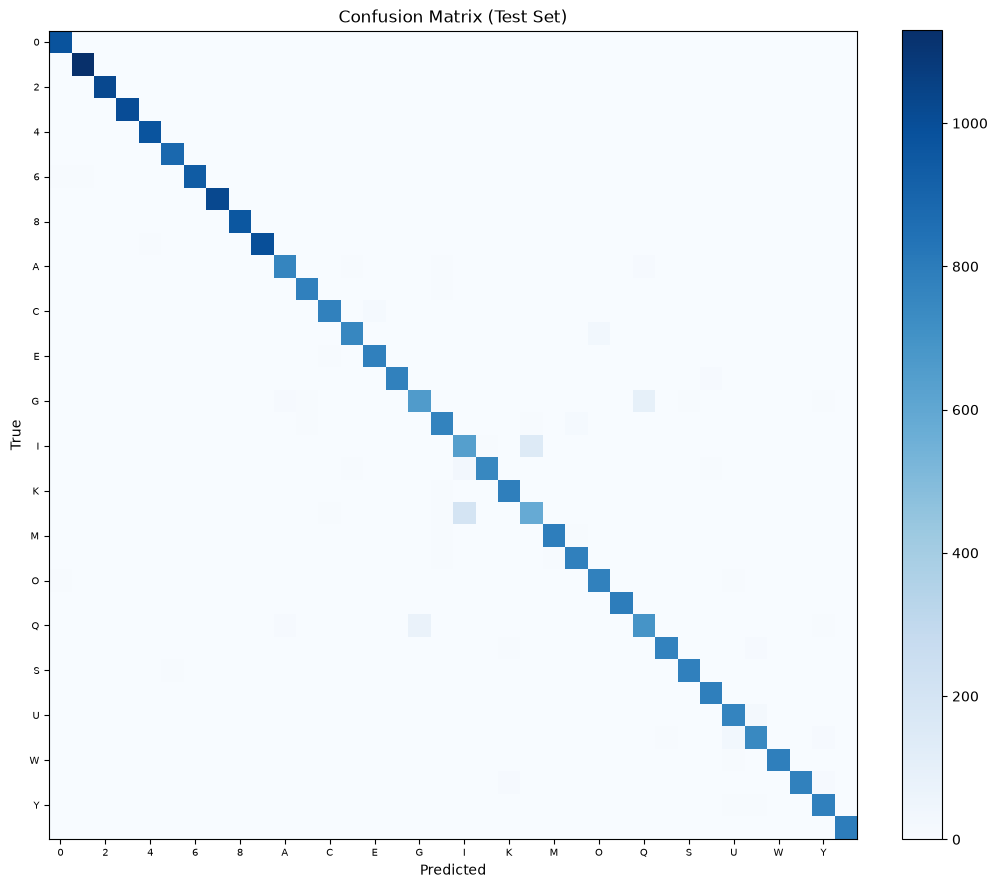

Top character confusions (excluding diagonal):
  True 'L' → Predicted 'I': 198 times
  True 'I' → Predicted 'L': 146 times
  True 'G' → Predicted 'Q': 97 times
  True 'Q' → Predicted 'G': 72 times
  True 'V' → Predicted 'U': 33 times


In [12]:
cm = confusion_matrix_np(y_true, y_pred, NUM_CLASSES)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
plt.colorbar(im, ax=ax, fraction=0.046)
ticks = range(0, NUM_CLASSES, 2)
ax.set_xticks(list(ticks)); ax.set_yticks(list(ticks))
ax.set_xticklabels([LABEL_MAP[i] for i in ticks], fontsize=7)
ax.set_yticklabels([LABEL_MAP[i] for i in ticks], fontsize=7)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
flat_order = np.argsort(cm_off.ravel())[::-1][:5]
print('Top character confusions (excluding diagonal):')
for rank in flat_order:
    ti, pi = divmod(int(rank), NUM_CLASSES)
    if cm_off[ti, pi] == 0:
        break
    print(f"  True '{LABEL_MAP[ti]}' → Predicted '{LABEL_MAP[pi]}': {cm_off[ti, pi]} times")


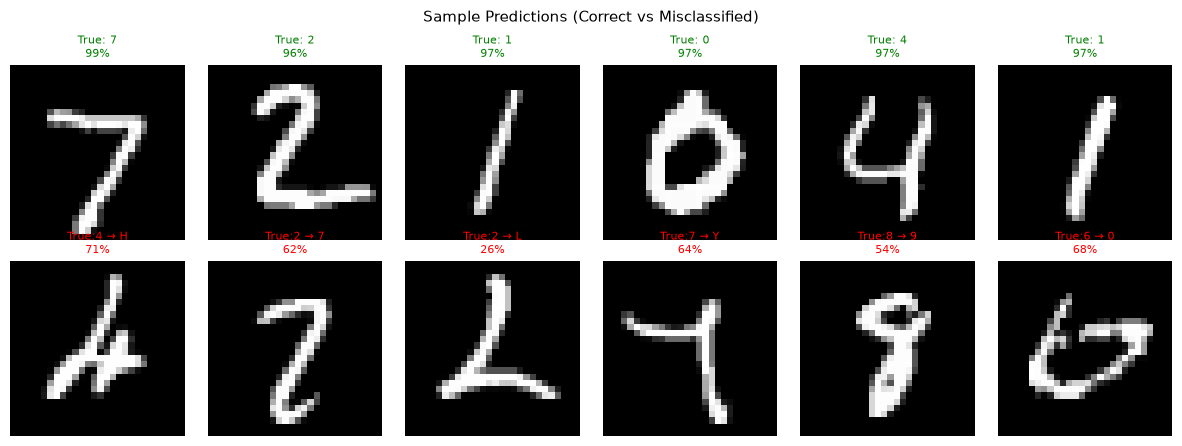

Correct shown: 6  |  Misclassified shown: 6


In [13]:
# Correct vs misclassified examples
correct_idx = [i for i, (t, p) in enumerate(zip(y_true, y_pred))
               if t == p and i < len(all_test_images)][:6]
misclass_idx = [i for i, (t, p) in enumerate(zip(y_true, y_pred))
                if t != p and i < len(all_test_images)][:6]

conf_cache = {}
model.eval()
with torch.no_grad():
    for idx in correct_idx + misclass_idx:
        probs = torch.softmax(model(all_test_images[idx].unsqueeze(0).to(device)), dim=1).squeeze()
        conf_cache[idx] = probs[y_pred[idx]].item() * 100

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ci, si in enumerate(correct_idx):
    axes[0, ci].imshow(denormalize(all_test_images[si]).squeeze().numpy(), cmap='gray')
    axes[0, ci].set_title(f"True: {LABEL_MAP[y_true[si]]}\n{conf_cache[si]:.0f}%",
                          fontsize=8, color='green')
    axes[0, ci].axis('off')
for ci, si in enumerate(misclass_idx):
    axes[1, ci].imshow(denormalize(all_test_images[si]).squeeze().numpy(), cmap='gray')
    axes[1, ci].set_title(
        f"True:{LABEL_MAP[y_true[si]]} → {LABEL_MAP[y_pred[si]]}\n{conf_cache[si]:.0f}%",
        fontsize=8, color='red')
    axes[1, ci].axis('off')
axes[0, 0].set_ylabel('Correct', fontsize=9, color='green')
axes[1, 0].set_ylabel('Misclassified', fontsize=9, color='red')
plt.suptitle('Sample Predictions (Correct vs Misclassified)', fontsize=11)
plt.tight_layout()
plt.show()
print(f'Correct shown: {len(correct_idx)}  |  Misclassified shown: {len(misclass_idx)}')


## 7. Custom Character Inference Pipeline

Preprocessing for an arbitrary grayscale character image:
1. Invert if background is light (ensure white-on-black)
2. Bounding-box crop of ink pixels
3. Aspect-preserving resize to fit in 20×20
4. Centre on a 28×28 canvas
5. Normalize with the same mean/std used in training
6. Softmax top-3 prediction

**Note:** Demonstrated on test-set glyphs (in-distribution).
Arbitrary external handwriting may differ in style and contrast.


Building character glyph cache...
Cached 36/36 classes


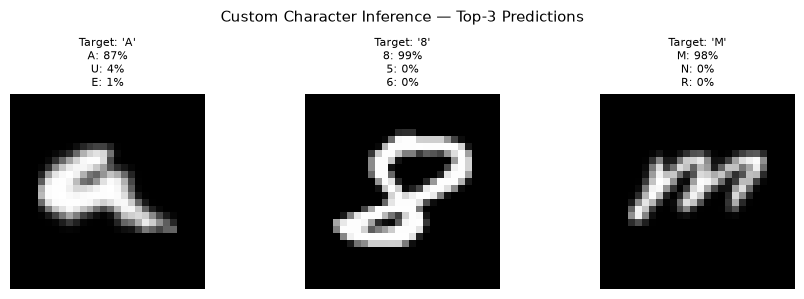

Inference pipeline ready.


In [14]:
def predict_custom_character(raw_img_array, model, label_map, device):
    """
    Preprocess and classify a grayscale character image.
    raw_img_array : 2-D array, values in [0, 255]
    Returns       : (28x28 canvas, list of (char, confidence%) top-3)
    """
    img = np.asarray(raw_img_array, dtype=np.float32)
    if img.mean() > 127:
        img = 255.0 - img
    coords = np.argwhere(img > 30)
    if len(coords):
        y0, x0 = coords.min(0)
        y1, x1 = coords.max(0) + 1
        crop = img[y0:y1, x0:x1]
    else:
        crop = img
    h, w = crop.shape
    scale = 20.0 / max(h, w)
    nh, nw = max(1, int(h * scale)), max(1, int(w * scale))
    pil_c = Image.fromarray(crop.astype(np.uint8)).resize((nw, nh), Image.Resampling.BILINEAR)
    canvas = np.zeros((28, 28), np.float32)
    sy, sx = (28 - nh) // 2, (28 - nw) // 2
    canvas[sy:sy + nh, sx:sx + nw] = np.asarray(pil_c, dtype=np.float32)
    t = torch.tensor(canvas).unsqueeze(0).unsqueeze(0) / 255.0
    t = (t - 0.5) / 0.5
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(t.to(device)), dim=1).squeeze()
    top_p, top_i = torch.topk(probs, 3)
    return canvas, [(label_map[i.item()], p.item() * 100) for i, p in zip(top_i, top_p)]


# Glyph cache: stop once all 36 classes are found (usually within a few hundred samples)
print('Building character glyph cache...')
char_cache = {}

# Digits from MNIST test
for img_t, lbl in mnist_test:
    name = LABEL_MAP[lbl]
    if name not in char_cache:
        char_cache[name] = img_t
    if sum(k.isdigit() for k in char_cache) == 10:
        break

# Letters from EMNIST test
for img_t, lbl in emnist_test:
    name = LABEL_MAP[lbl]
    if name not in char_cache:
        char_cache[name] = img_t
    if len(char_cache) == NUM_CLASSES:
        break

print(f'Cached {len(char_cache)}/{NUM_CLASSES} classes')
missing = [c for c in CLASS_NAMES if c not in char_cache]
if missing:
    print('WARNING missing classes:', missing)

demo_chars = [c for c in ['A', '8', 'M'] if c in char_cache]
if len(demo_chars) < 3:
    demo_chars = list(char_cache.keys())[:3]

fig, axes = plt.subplots(1, len(demo_chars), figsize=(3 * len(demo_chars), 3))
if len(demo_chars) == 1:
    axes = [axes]
for i, ch in enumerate(demo_chars):
    raw = (denormalize(char_cache[ch]).squeeze().numpy() * 255).astype(np.uint8)
    canvas, top3 = predict_custom_character(raw, model, LABEL_MAP, device)
    axes[i].imshow(canvas, cmap='gray')
    axes[i].set_title(
        f"Target: '{ch}'\n" + '\n'.join([f'{c}: {p:.0f}%' for c, p in top3]),
        fontsize=8)
    axes[i].axis('off')
plt.suptitle('Custom Character Inference — Top-3 Predictions', fontsize=11)
plt.tight_layout()
plt.show()
print('Inference pipeline ready.')

## 8. Optional CRNN Extension (Untrained Architecture Demo)

A Convolutional Recurrent Neural Network (CNN feature extractor + bidirectional LSTM)
is a standard approach for **sequence** recognition (words / lines). The cell below
only verifies that the architecture builds and produces the expected tensor shapes.

**This CRNN is not trained.** Real word recognition requires a word-level dataset
(e.g. IAM Handwriting) and CTC loss training.


In [15]:
class CRNN(nn.Module):
    """Lightweight CRNN for illustration only — not trained."""
    def __init__(self, num_classes=37, hidden_size=128):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(True), nn.MaxPool2d((2, 1), (2, 1)),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(True),
            nn.AdaptiveAvgPool2d((1, None)),
        )
        self.rnn = nn.LSTM(128, hidden_size, bidirectional=True, num_layers=2, batch_first=True)
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        feats = self.cnn(x).squeeze(2).permute(0, 2, 1)
        out, _ = self.rnn(feats)
        return self.fc(out)


crnn = CRNN(num_classes=NUM_CLASSES + 1)
dummy_word = torch.randn(1, 1, 28, 140)
with torch.no_grad():
    crnn_out = crnn(dummy_word)
total_crnn = sum(p.numel() for p in crnn.parameters() if p.requires_grad)
print('[UNTRAINED DEMO] CRNN architecture:')
print(f'  Input:      {tuple(dummy_word.shape)}')
print(f'  Output:     {tuple(crnn_out.shape)}  (T time-steps x 37 class logits)')
print(f'  Parameters: {total_crnn:,}')
print('Training requires a word-level dataset with transcriptions (e.g. IAM Handwriting).')


[UNTRAINED DEMO] CRNN architecture:
  Input:      (1, 1, 28, 140)
  Output:     (1, 70, 37)  (T time-steps x 37 class logits)
  Parameters: 891,045
Training requires a word-level dataset with transcriptions (e.g. IAM Handwriting).


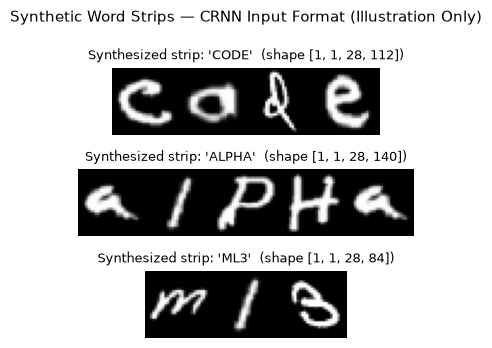

These strips are visual illustrations only — the CRNN above is not trained on them.


In [16]:
# Synthetic word strips (illustration of CRNN input format only)
target_words = ['CODE', 'ALPHA', 'ML3']
fig, axes = plt.subplots(len(target_words), 1, figsize=(8, 3.5))
for ri, word in enumerate(target_words):
    strip = torch.cat([char_cache[ch] for ch in word], dim=2)
    axes[ri].imshow(denormalize(strip).squeeze().numpy(), cmap='gray')
    axes[ri].set_title(
        f"Synthesized strip: '{word}'  (shape [1, 1, 28, {28 * len(word)}])",
        fontsize=9)
    axes[ri].axis('off')
plt.suptitle('Synthetic Word Strips — CRNN Input Format (Illustration Only)', fontsize=11)
plt.tight_layout()
plt.show()
print('These strips are visual illustrations only — the CRNN above is not trained on them.')


## 9. Conclusion, Limitations & Future Work

### What was built
| Step | Component | Result |
|------|-----------|--------|
| 1 | Dataset ingestion | MNIST + EMNIST Letters → 36 classes |
| 1 | Orientation | `Image.TRANSPOSE` verified on raw samples |
| 2 | Augmentation | Train-only rotation + affine |
| 3 | CharCNN | ~397k parameters, 3-stage conv stack |
| 4 | Training | Best checkpoint selected by validation accuracy |
| 5 | Test evaluation | Full 30,800-sample held-out set |
| 6 | Custom inference | Crop → resize → centre → top-3 softmax |
| 7 | CRNN | Untrained architecture demo only |

### Limitations
- **Short training:** 3 epochs on CPU; more epochs (or a GPU) would likely improve accuracy.
- **Class balance:** Digits have more samples per class than letters in the combined pool.
- **Uppercase only:** EMNIST Letters does not include lowercase.
- **CRNN not trained:** Word recognition needs a sequence dataset and CTC training.
- **Distribution shift:** Custom inference works best on MNIST/EMNIST-like images.

### Future improvements
- Train longer with early stopping; try mild class weighting.
- Report per-class F1 for confusable pairs (I/L, 0/O, 8/B, …).
- Train a CRNN on IAM or a synthetic word corpus.
- Quantize / export the CharCNN for mobile deployment.
